In [ ]:
# ===== SETUP: imports, data loading, helper functions (sirf ek baar) =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.gridspec import GridSpec
import warnings
warnings.filterwarnings("ignore")

DATA_DIR = "."   

FILES = {
    "ops":     "1_Hospital_Operation.xlsx",
    "patient": "2_Patient_Analytics.xlsx",
    "disease": "3_Disease_Analytics.xlsx",
    "doctor":  "4_Doctor_Performance.xlsx",
    "cost":    "5_Cost_and_Revenue.xlsx",
}

# Har file ki saari sheets ek dict mein: data["ops"]["Raw Data"], data["ops"]["Ward Utilization"] ...
data = {k: pd.read_excel(os.path.join(DATA_DIR, f), sheet_name=None) for k, f in FILES.items()}

ops_raw     = data["ops"]["Raw Data"].copy()
patient_raw = data["patient"]["Raw Data"].copy()
disease_raw = data["disease"]["Raw Data"].copy()
doctor_raw  = data["doctor"]["Raw Data"].copy()
cost_raw    = data["cost"]["Raw Data"].copy()

ops_raw["Admission Date"] = pd.to_datetime(ops_raw["Admission Date"])
ops_raw["Discharge Date"] = pd.to_datetime(ops_raw["Discharge Date"])

# ---- Look & feel ----
C = {"blue":"#2F6DB5", "teal":"#1B9E8A", "orange":"#E8833A", "red":"#C8453F",
     "purple":"#7A5BB0", "grey":"#8A94A0", "ink":"#1F2933", "bg":"#F6F8FA"}
PALETTE = [C["blue"], C["teal"], C["orange"], C["purple"], C["red"], C["grey"]]
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "font.size": 10, "axes.grid": True, "grid.alpha": .25,
    "axes.axisbelow": True,
})

def inr(x):
    """Rupees ko Cr / L format mein dikhao."""
    if abs(x) >= 1e7: return f"₹{x/1e7:,.2f} Cr"
    if abs(x) >= 1e5: return f"₹{x/1e5:,.2f} L"
    return f"₹{x:,.0f}"

def new_dashboard(title, kpis, rows, cols, height_per_row=4.2):
    """KPI strip + (rows x cols) chart grid wali figure banata hai. Axes ki 2D list return karta hai."""
    fig = plt.figure(figsize=(6.2*cols, 1.5 + height_per_row*rows), facecolor=C["bg"])
    gs = GridSpec(rows+1, cols, figure=fig, height_ratios=[0.5]+[2]*rows, hspace=.5, wspace=.28, top=.92, bottom=.05, left=.06, right=.98)
    fig.suptitle(title, fontsize=20, fontweight="bold", color=C["ink"], x=.01, ha="left", y=.985)
    ax = fig.add_subplot(gs[0, :]); ax.axis("off")
    n = len(kpis)
    for i, (label, value) in enumerate(kpis):
        x0 = i/n + .005
        ax.add_patch(plt.Rectangle((x0, .04), 1/n-.012, .88, transform=ax.transAxes, clip_on=False,
                                   facecolor="white", edgecolor="#D5DBE1", lw=1))
        ax.text(x0+.5/n-.006, .60, value, transform=ax.transAxes, ha="center", va="center",
                fontsize=17, fontweight="bold", color=C["blue"])
        ax.text(x0+.5/n-.006, .22, label, transform=ax.transAxes, ha="center", va="center",
                fontsize=9.5, color=C["grey"])
    axes = [[fig.add_subplot(gs[r+1, c]) for c in range(cols)] for r in range(rows)]
    return fig, axes

def bar_labels(ax, fmt="{:,.0f}", horizontal=False, pad=3):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if horizontal: ax.annotate(fmt.format(v), (v, p.get_y()+p.get_height()/2), xytext=(pad,0),
                                   textcoords="offset points", va="center", fontsize=9)
        else: ax.annotate(fmt.format(v), (p.get_x()+p.get_width()/2, v), xytext=(0,pad),
                          textcoords="offset points", ha="center", fontsize=9)

def donut(ax, labels, values, colors=None):
    colors = colors or PALETTE
    w, _, t = ax.pie(values, labels=labels, colors=colors[:len(values)], autopct="%1.1f%%",
                     startangle=90, pctdistance=.78, wedgeprops=dict(width=.42, edgecolor="white"),
                     textprops=dict(fontsize=10))
    for x in t: x.set_color("white"); x.set_fontweight("bold")
    ax.grid(False)

print("✅ Data loaded:", {k: v.shape for k, v in
      dict(ops=ops_raw, patient=patient_raw, disease=disease_raw, doctor=doctor_raw, cost=cost_raw).items()})

✅ Data loaded: {'ops': (1000, 6), 'patient': (1000, 5), 'disease': (1000, 5), 'doctor': (1000, 5), 'cost': (1000, 5)}


---
## 📊 Dashboard 1 — Hospital Operation
Ward utilization, admission status, average stay aur monthly admissions.

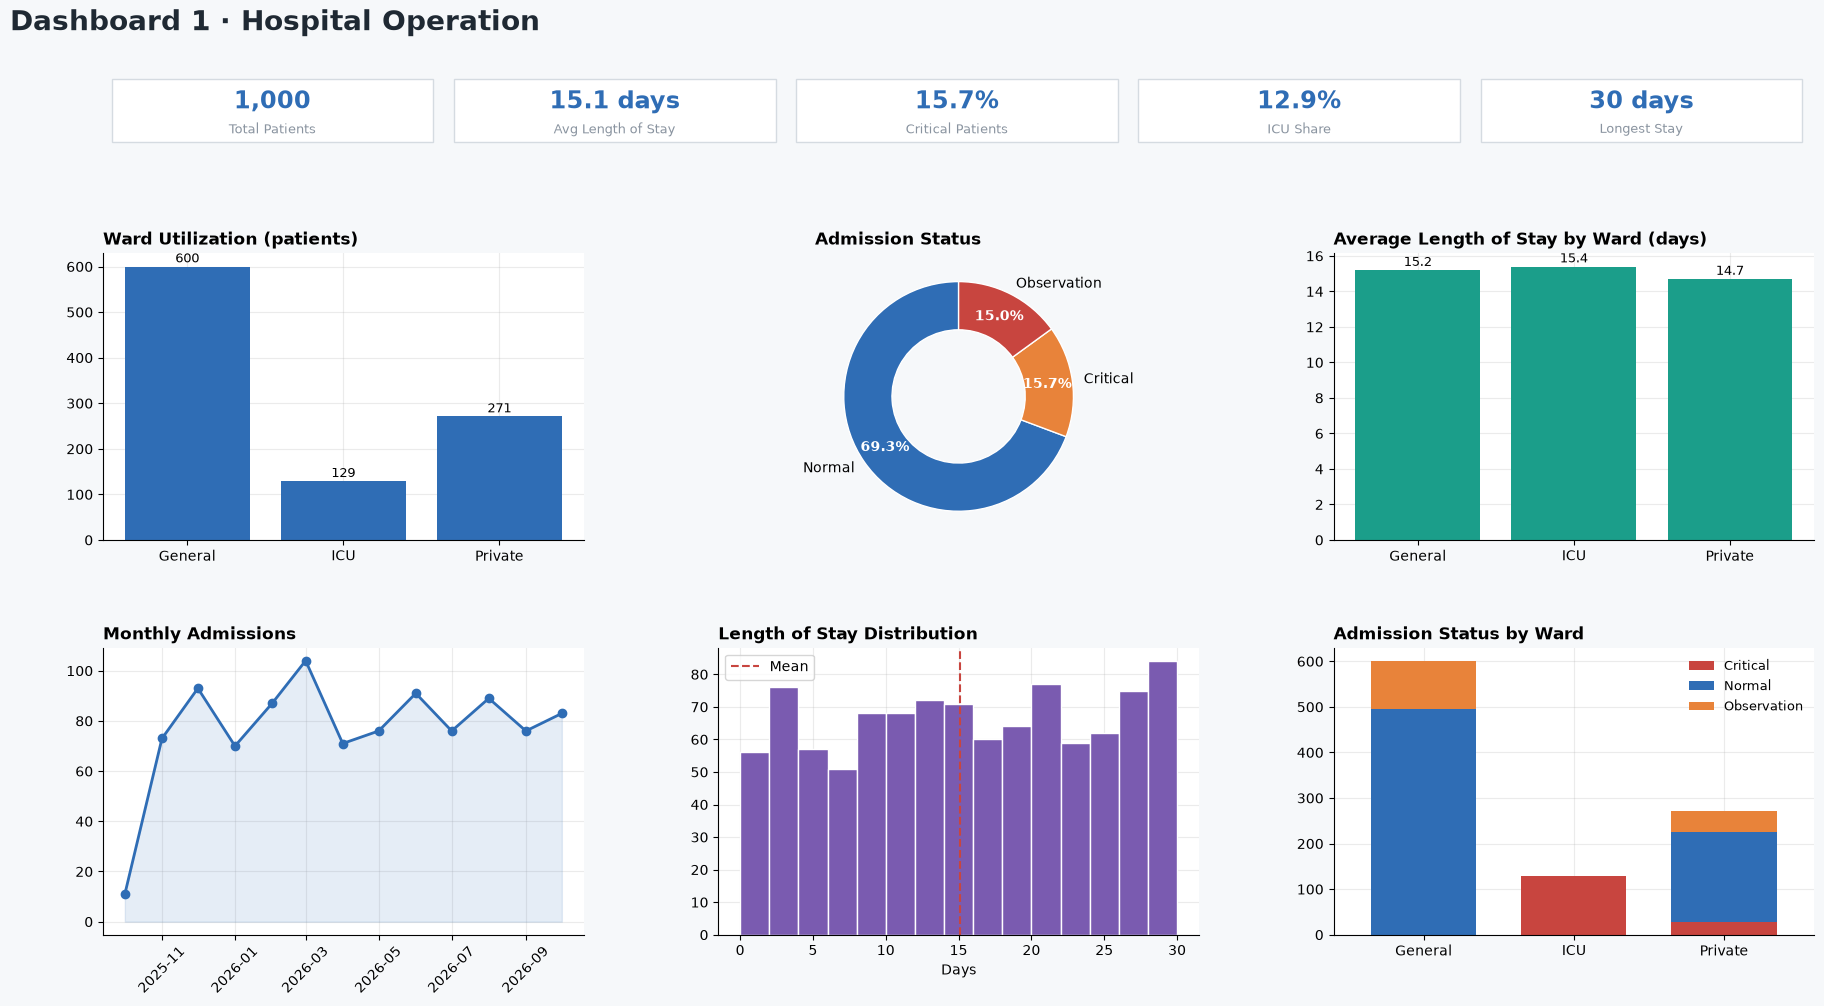

In [3]:
ward_util = data["ops"]["Ward Utilization"]
adm_stat  = data["ops"]["Admission Status"]
avg_stay  = data["ops"]["Avg Stay"]

kpis = [
    ("Total Patients",        f"{len(ops_raw):,}"),
    ("Avg Length of Stay",    f"{ops_raw['Length of Stay (Days)'].mean():.1f} days"),
    ("Critical Patients",     f"{(ops_raw['Admission Status']=='Critical').mean():.1%}"),
    ("ICU Share",             f"{(ops_raw['Ward Type']=='ICU').mean():.1%}"),
    ("Longest Stay",          f"{ops_raw['Length of Stay (Days)'].max()} days"),
]
fig, ax = new_dashboard("Dashboard 1 · Hospital Operation", kpis, 2, 3)

ax[0][0].bar(ward_util["Ward Type"], ward_util["Total Patients"], color=C["blue"])
ax[0][0].set_title("Ward Utilization (patients)"); bar_labels(ax[0][0])

order = adm_stat.sort_values("Total Patients", ascending=False)
donut(ax[0][1], order["Admission Status"], order["Total Patients"], [C["blue"], C["orange"], C["red"]])
ax[0][1].set_title("Admission Status")

ax[0][2].bar(avg_stay["Ward Type"], avg_stay["Avg Length of Stay"], color=C["teal"])
ax[0][2].set_title("Average Length of Stay by Ward (days)"); bar_labels(ax[0][2], "{:.1f}")

monthly = ops_raw.set_index("Admission Date").resample("MS").size()
ax[1][0].plot(monthly.index, monthly.values, marker="o", color=C["blue"], lw=2)
ax[1][0].fill_between(monthly.index, monthly.values, alpha=.12, color=C["blue"])
ax[1][0].set_title("Monthly Admissions"); ax[1][0].tick_params(axis="x", rotation=45)

ax[1][1].hist(ops_raw["Length of Stay (Days)"], bins=15, color=C["purple"], edgecolor="white")
ax[1][1].axvline(ops_raw["Length of Stay (Days)"].mean(), color=C["red"], ls="--", label="Mean")
ax[1][1].set_title("Length of Stay Distribution"); ax[1][1].set_xlabel("Days"); ax[1][1].legend()

ct = pd.crosstab(ops_raw["Ward Type"], ops_raw["Admission Status"])
ct.plot(kind="bar", stacked=True, ax=ax[1][2], color=[C["red"], C["blue"], C["orange"]], width=.7)
ax[1][2].set_title("Admission Status by Ward"); ax[1][2].set_xlabel(""); ax[1][2].tick_params(axis="x", rotation=0)
ax[1][2].legend(frameon=False, fontsize=9)
plt.show()

---
## 👥 Dashboard 2 — Patient Analytics
Gender, age group aur city-wise patient distribution.

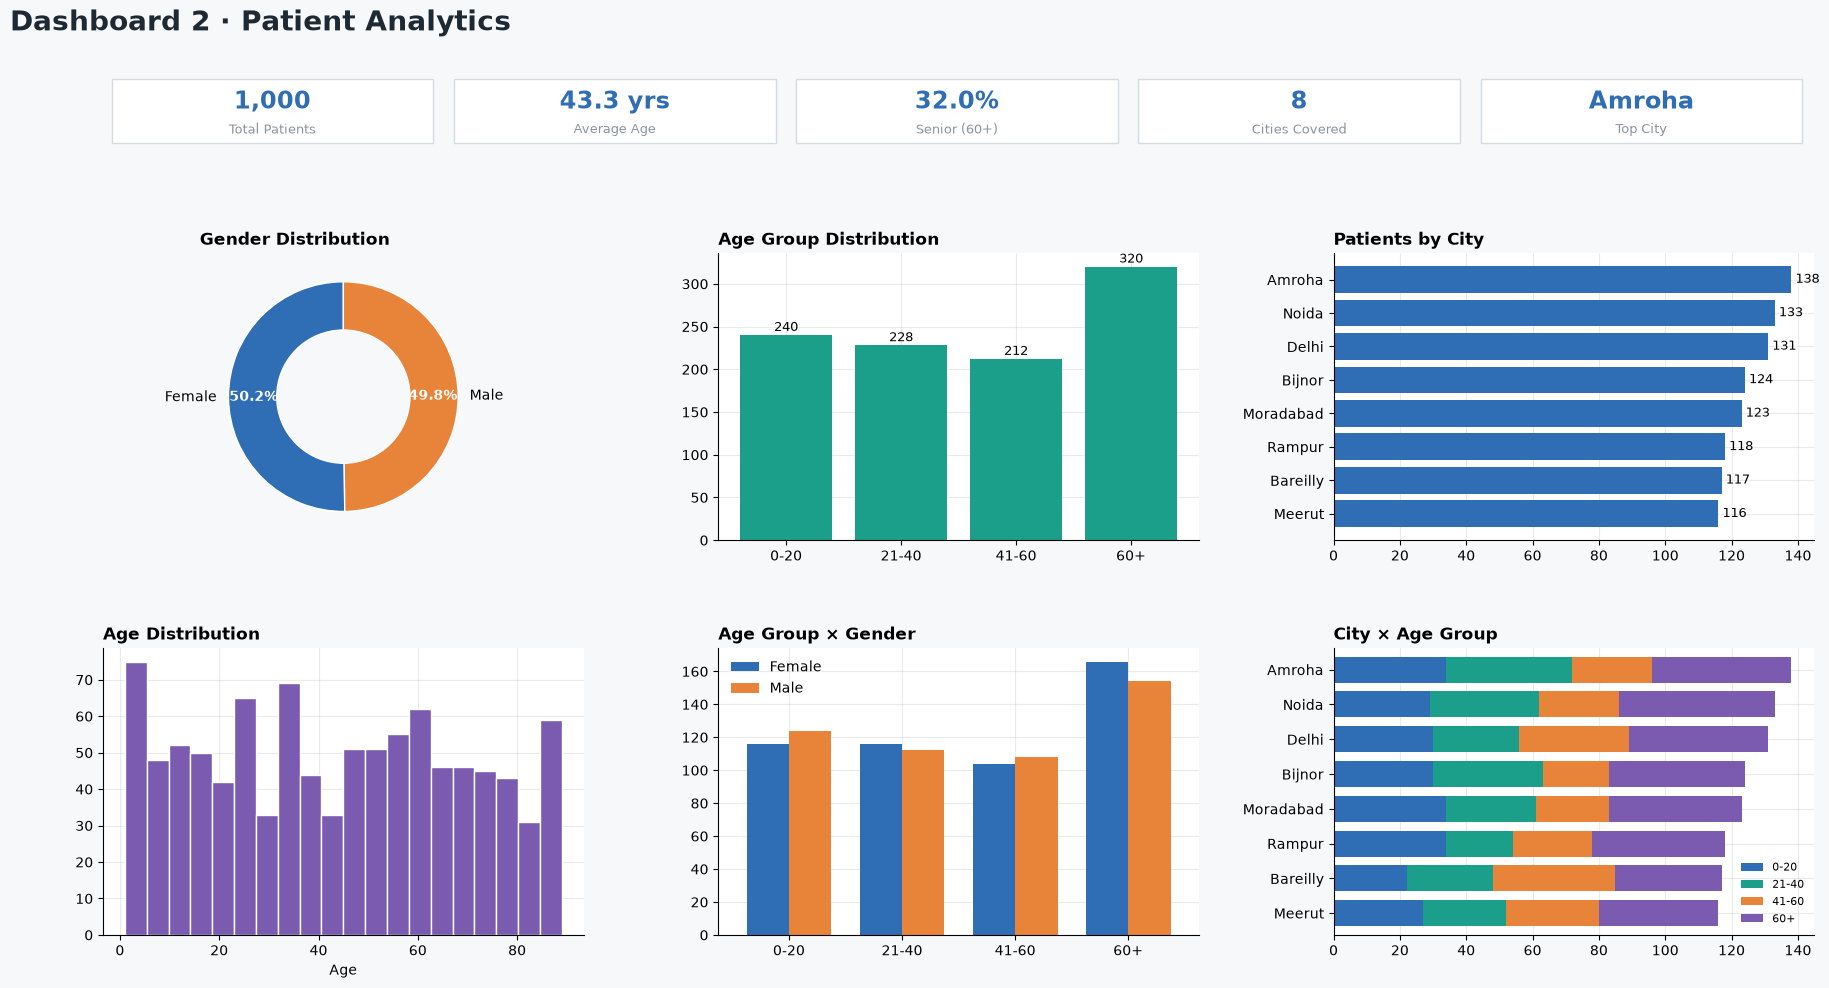

In [4]:
gender = data["patient"]["Gender Distribution"].dropna()
age_g  = data["patient"]["Age Group Distribution"].dropna()
city   = data["patient"]["City Distribution"].dropna().sort_values("Patient Count")
age_order = ["0-20", "21-40", "41-60", "60+"]

kpis = [
    ("Total Patients", f"{len(patient_raw):,}"),
    ("Average Age",    f"{patient_raw['Age'].mean():.1f} yrs"),
    ("Senior (60+)",   f"{(patient_raw['Age Group']=='60+').mean():.1%}"),
    ("Cities Covered", f"{patient_raw['City'].nunique()}"),
    ("Top City",       city.iloc[-1]["City"]),
]
fig, ax = new_dashboard("Dashboard 2 · Patient Analytics", kpis, 2, 3)

donut(ax[0][0], gender["Gender"], gender["Patient Count"], [C["blue"], C["orange"]])
ax[0][0].set_title("Gender Distribution")

a = age_g.set_index("Age Group").reindex(age_order).reset_index()
ax[0][1].bar(a["Age Group"], a["Patient Count"], color=C["teal"]); bar_labels(ax[0][1])
ax[0][1].set_title("Age Group Distribution")

ax[0][2].barh(city["City"], city["Patient Count"], color=C["blue"]); bar_labels(ax[0][2], horizontal=True)
ax[0][2].set_title("Patients by City")

ax[1][0].hist(patient_raw["Age"], bins=20, color=C["purple"], edgecolor="white")
ax[1][0].set_title("Age Distribution"); ax[1][0].set_xlabel("Age")

ct = pd.crosstab(patient_raw["Age Group"], patient_raw["Gender"]).reindex(age_order)
ct.plot(kind="bar", ax=ax[1][1], color=[C["blue"], C["orange"]], width=.75)
ax[1][1].set_title("Age Group × Gender"); ax[1][1].set_xlabel(""); ax[1][1].tick_params(axis="x", rotation=0)
ax[1][1].legend(frameon=False)

top = pd.crosstab(patient_raw["City"], patient_raw["Age Group"])[age_order]
top = top.loc[top.sum(axis=1).sort_values().index]
top.plot(kind="barh", stacked=True, ax=ax[1][2], color=PALETTE[:4], width=.75)
ax[1][2].set_title("City × Age Group"); ax[1][2].set_ylabel(""); ax[1][2].legend(frameon=False, fontsize=8)
plt.show()

---
## 🦠 Dashboard 3 — Disease Analytics
Disease-wise patient count, severity aur demographics.

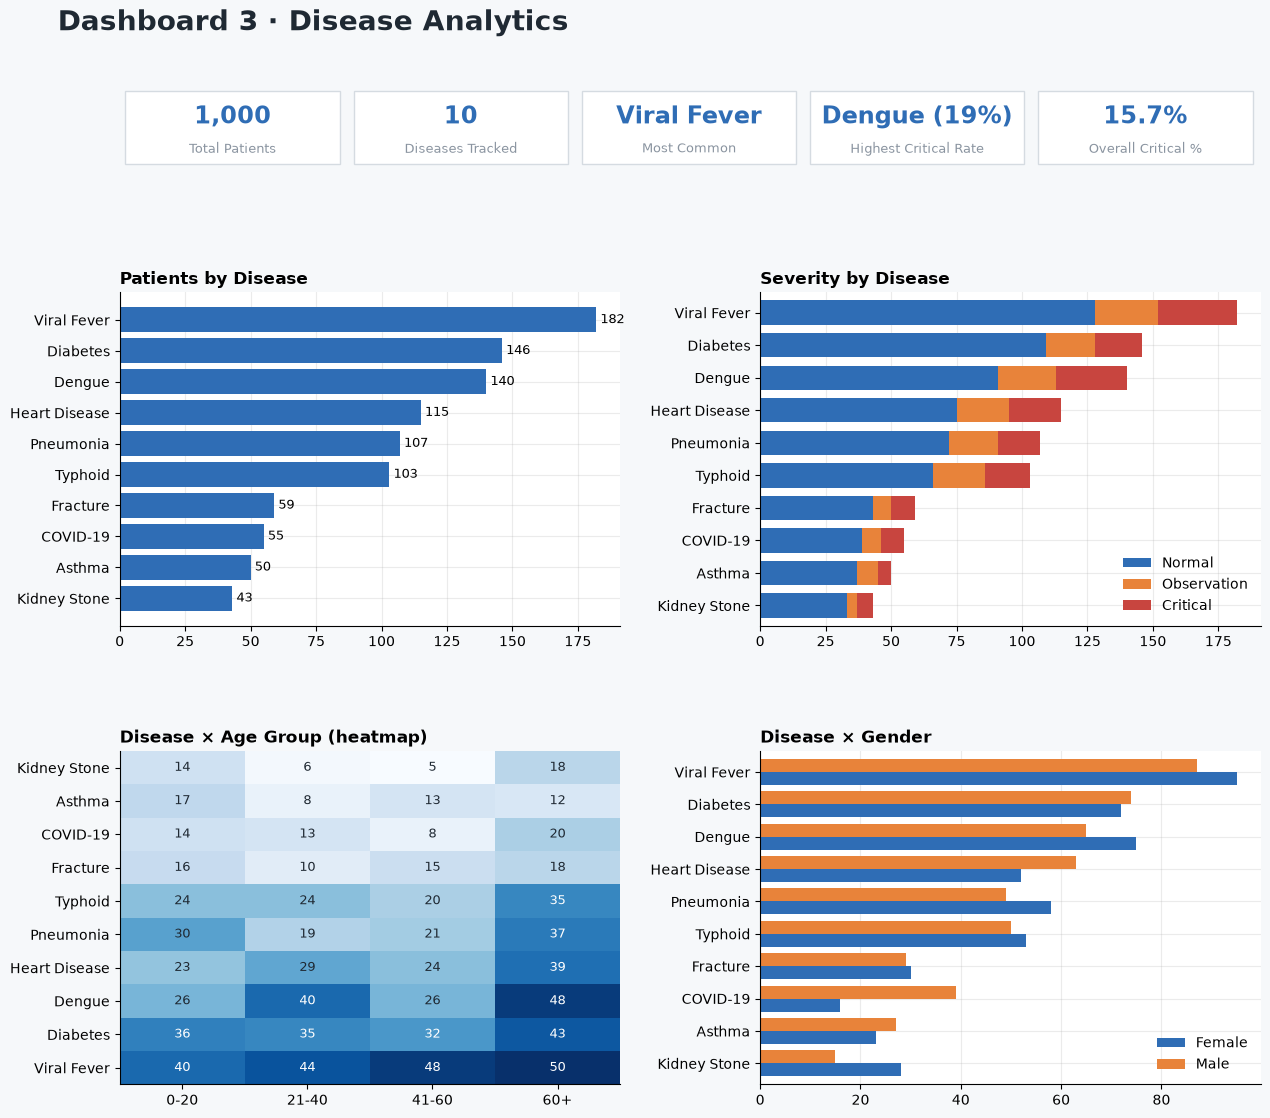

In [5]:
tot  = data["disease"]["Total by Disease"].sort_values("Patient Count")
sev  = data["disease"]["Severity by Disease"].set_index("Disease")
age_order = ["0-20", "21-40", "41-60", "60+"]

sev_rate = (sev["Critical"] / sev.sum(axis=1)).sort_values()
kpis = [
    ("Total Patients",       f"{len(disease_raw):,}"),
    ("Diseases Tracked",     f"{disease_raw['Disease'].nunique()}"),
    ("Most Common",          tot.iloc[-1]["Disease"]),
    ("Highest Critical Rate",f"{sev_rate.index[-1]} ({sev_rate.iloc[-1]:.0%})"),
    ("Overall Critical %",   f"{(disease_raw['Admission Status']=='Critical').mean():.1%}"),
]
fig, ax = new_dashboard("Dashboard 3 · Disease Analytics", kpis, 2, 2, height_per_row=5)

ax[0][0].barh(tot["Disease"], tot["Patient Count"], color=C["blue"]); bar_labels(ax[0][0], horizontal=True)
ax[0][0].set_title("Patients by Disease")

s = sev.loc[tot["Disease"]]
s[["Normal", "Observation", "Critical"]].plot(kind="barh", stacked=True, ax=ax[0][1],
        color=[C["blue"], C["orange"], C["red"]], width=.75)
ax[0][1].set_title("Severity by Disease"); ax[0][1].set_ylabel(""); ax[0][1].legend(frameon=False)

hm = pd.crosstab(disease_raw["Disease"], disease_raw["Age Group"])[age_order].loc[tot["Disease"]]
im = ax[1][0].imshow(hm.values, cmap="Blues", aspect="auto")
ax[1][0].set_xticks(range(len(hm.columns)), hm.columns); ax[1][0].set_yticks(range(len(hm.index)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]; ax[1][0].text(j, i, v, ha="center", va="center",
                                           color="white" if v > hm.values.max()*.6 else C["ink"], fontsize=9)
ax[1][0].set_title("Disease × Age Group (heatmap)"); ax[1][0].grid(False)

g = pd.crosstab(disease_raw["Disease"], disease_raw["Gender"]).loc[tot["Disease"]]
g.plot(kind="barh", ax=ax[1][1], color=[C["blue"], C["orange"]], width=.8)
ax[1][1].set_title("Disease × Gender"); ax[1][1].set_ylabel(""); ax[1][1].legend(frameon=False)
plt.show()

---
## 🩺 Dashboard 4 — Doctor Performance
Har doctor ke patients, revenue aur avg revenue per patient.

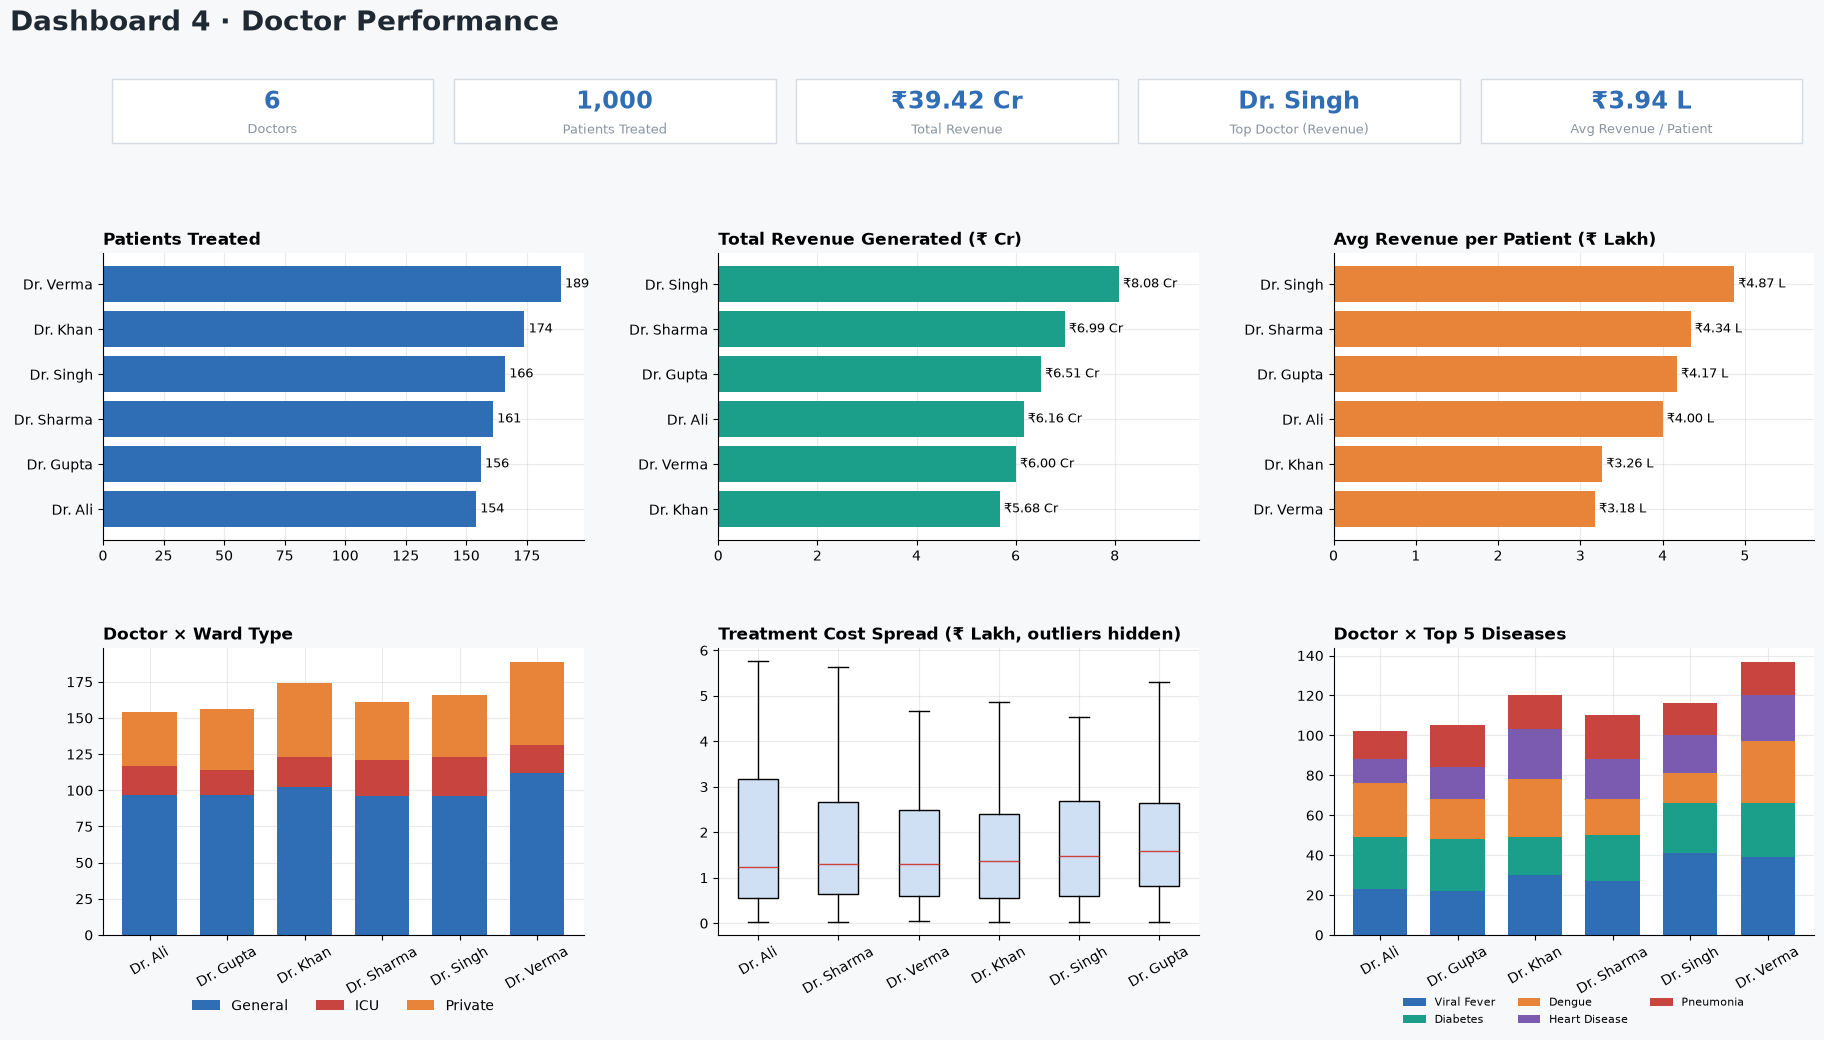

In [6]:
kp = data["doctor"]["Doctor KPIs"].copy()
kp["short"] = kp["Doctor Name"].str.replace(r"\s*\(.*\)", "", regex=True)

best = kp.loc[kp["Total_Revenue_Generated_INR"].idxmax()]
kpis = [
    ("Doctors",               f"{len(kp)}"),
    ("Patients Treated",      f"{kp['Patients_Treated'].sum():,}"),
    ("Total Revenue",         inr(kp["Total_Revenue_Generated_INR"].sum())),
    ("Top Doctor (Revenue)",  best["short"]),
    ("Avg Revenue / Patient", inr(doctor_raw["Treatment Cost (INR)"].mean())),
]
fig, ax = new_dashboard("Dashboard 4 · Doctor Performance", kpis, 2, 3)

k = kp.sort_values("Patients_Treated")
ax[0][0].barh(k["short"], k["Patients_Treated"], color=C["blue"]); bar_labels(ax[0][0], horizontal=True)
ax[0][0].set_title("Patients Treated")

k = kp.sort_values("Total_Revenue_Generated_INR")
ax[0][1].barh(k["short"], k["Total_Revenue_Generated_INR"]/1e7, color=C["teal"])
bar_labels(ax[0][1], "₹{:.2f} Cr", horizontal=True); ax[0][1].set_title("Total Revenue Generated (₹ Cr)")
ax[0][1].margins(x=.2)

k = kp.sort_values("Avg Revenue per Patient")
ax[0][2].barh(k["short"], k["Avg Revenue per Patient"]/1e5, color=C["orange"])
bar_labels(ax[0][2], "₹{:.2f} L", horizontal=True); ax[0][2].set_title("Avg Revenue per Patient (₹ Lakh)")
ax[0][2].margins(x=.2)

d = doctor_raw.assign(Doctor=doctor_raw["Doctor Name"].str.replace(r"\s*\(.*\)", "", regex=True))
ct = pd.crosstab(d["Doctor"], d["Ward Type"])
ct.plot(kind="bar", stacked=True, ax=ax[1][0], color=[C["blue"], C["red"], C["orange"]], width=.7)
ax[1][0].set_title("Doctor × Ward Type"); ax[1][0].set_xlabel(""); ax[1][0].tick_params(axis="x", rotation=30)
ax[1][0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.18))

order = d.groupby("Doctor")["Treatment Cost (INR)"].median().sort_values().index
ax[1][1].boxplot([d.loc[d["Doctor"]==n, "Treatment Cost (INR)"]/1e5 for n in order],
                 showfliers=False, patch_artist=True, boxprops=dict(facecolor="#CFE0F5"), medianprops=dict(color=C["red"]))
ax[1][1].set_xticks(range(1, len(order)+1), order)
ax[1][1].set_title("Treatment Cost Spread (₹ Lakh, outliers hidden)"); ax[1][1].tick_params(axis="x", rotation=30)

dd = d.groupby(["Doctor", "Disease"]).size().unstack(fill_value=0)
top_dis = dd.sum().sort_values(ascending=False).head(5).index
dd[top_dis].plot(kind="bar", stacked=True, ax=ax[1][2], color=PALETTE[:5], width=.7)
ax[1][2].set_title("Doctor × Top 5 Diseases"); ax[1][2].set_xlabel(""); ax[1][2].tick_params(axis="x", rotation=30)
ax[1][2].legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.18))
plt.show()

---
## 💰 Dashboard 5 — Cost & Revenue
Payment mode, disease aur ward ke hisaab se revenue aur treatment cost.

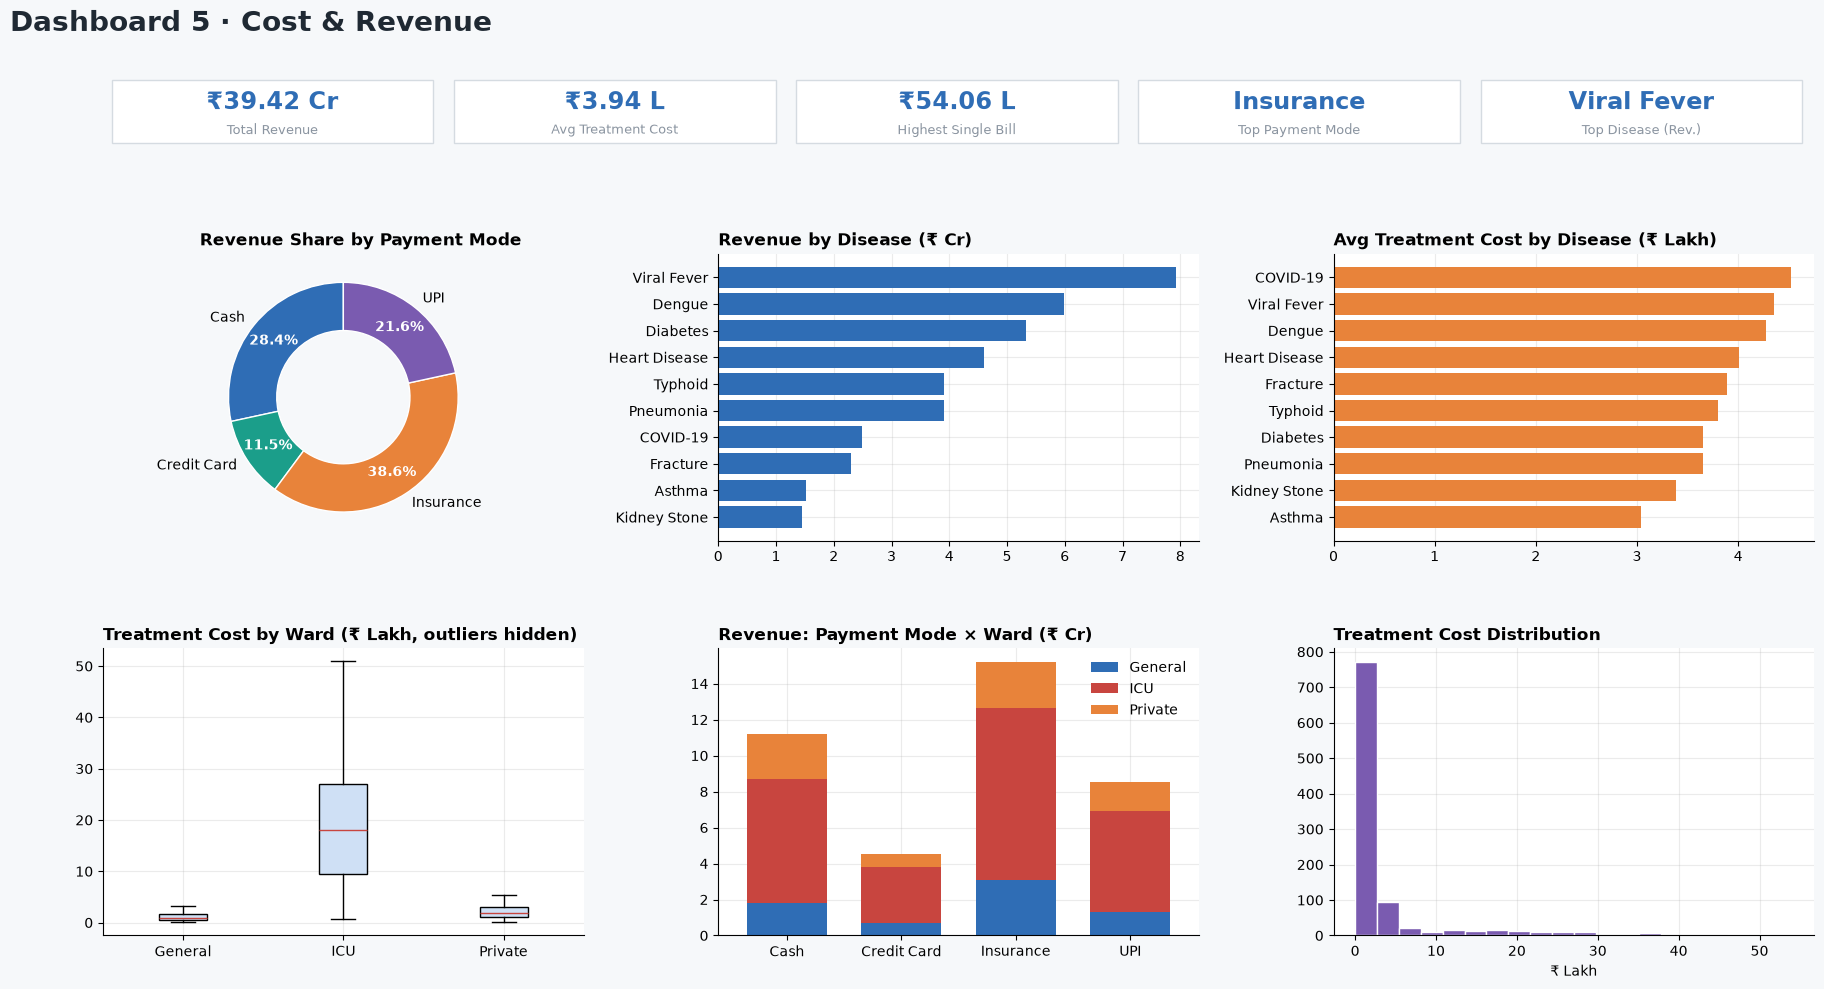

In [7]:
rpm = data["cost"]["Revenue by Payment Mode"].copy()
rds = data["cost"]["Revenue by Disease"].copy()

kpis = [
    ("Total Revenue",       inr(cost_raw["Treatment Cost (INR)"].sum())),
    ("Avg Treatment Cost",  inr(cost_raw["Treatment Cost (INR)"].mean())),
    ("Highest Single Bill", inr(cost_raw["Treatment Cost (INR)"].max())),
    ("Top Payment Mode",    rpm.loc[rpm["Total_Revenue_INR"].idxmax(), "Payment Mode"]),
    ("Top Disease (Rev.)",  rds.loc[rds["Total_Revenue_INR"].idxmax(), "Disease"]),
]
fig, ax = new_dashboard("Dashboard 5 · Cost & Revenue", kpis, 2, 3)

donut(ax[0][0], rpm["Payment Mode"], rpm["Total_Revenue_INR"], PALETTE)
ax[0][0].set_title("Revenue Share by Payment Mode")

r = rds.sort_values("Total_Revenue_INR")
ax[0][1].barh(r["Disease"], r["Total_Revenue_INR"]/1e7, color=C["blue"])
ax[0][1].set_title("Revenue by Disease (₹ Cr)")

r = rds.sort_values("Avg_Cost_INR")
ax[0][2].barh(r["Disease"], r["Avg_Cost_INR"]/1e5, color=C["orange"])
ax[0][2].set_title("Avg Treatment Cost by Disease (₹ Lakh)")

wards = sorted(cost_raw["Ward Type"].unique())
ax[1][0].boxplot([cost_raw.loc[cost_raw["Ward Type"]==w, "Treatment Cost (INR)"]/1e5 for w in wards],
                 showfliers=False, patch_artist=True, boxprops=dict(facecolor="#CFE0F5"),
                 medianprops=dict(color=C["red"]))
ax[1][0].set_xticks(range(1, len(wards)+1), wards)
ax[1][0].set_title("Treatment Cost by Ward (₹ Lakh, outliers hidden)")

pw = cost_raw.pivot_table(index="Payment Mode", columns="Ward Type", values="Treatment Cost (INR)", aggfunc="sum")/1e7
pw.plot(kind="bar", stacked=True, ax=ax[1][1], color=[C["blue"], C["red"], C["orange"]], width=.7)
ax[1][1].set_title("Revenue: Payment Mode × Ward (₹ Cr)"); ax[1][1].set_xlabel("")
ax[1][1].tick_params(axis="x", rotation=0); ax[1][1].legend(frameon=False)

ax[1][2].hist(cost_raw["Treatment Cost (INR)"]/1e5, bins=20, color=C["purple"], edgecolor="white")
ax[1][2].set_title("Treatment Cost Distribution"); ax[1][2].set_xlabel("₹ Lakh")
plt.show()

---
## ⭐ MAJOR DASHBOARD — Complete Hospital Overview

Sabhi 5 files ko `Patient ID` ke through jodkar ek **master dataset** banaya gaya hai, taaki operations, patient, disease, doctor aur revenue — sab ek hi jagah dikhe.

In [8]:
# ----- Master dataset: 5 files ko Patient ID par merge -----
master = (ops_raw
    .merge(patient_raw[["Patient ID", "Age", "Age Group", "Gender", "City"]], on="Patient ID", how="left")
    .merge(doctor_raw[["Patient ID", "Doctor Name", "Disease", "Treatment Cost (INR)"]], on="Patient ID", how="left")
    .merge(cost_raw[["Patient ID", "Payment Mode"]], on="Patient ID", how="left"))
master["Doctor"] = master["Doctor Name"].str.replace(r"\s*\(.*\)", "", regex=True)
master["Month"] = master["Admission Date"].dt.to_period("M").dt.to_timestamp()

# Sanity check: alag-alag files ka overlapping data match karta hai ya nahi
checks = {
    "Disease (doctor vs disease file)": (doctor_raw.set_index("Patient ID")["Disease"] == disease_raw.set_index("Patient ID")["Disease"]).all(),
    "Disease (doctor vs cost file)":    (doctor_raw.set_index("Patient ID")["Disease"] == cost_raw.set_index("Patient ID")["Disease"]).all(),
    "Cost (doctor vs cost file)":       (doctor_raw.set_index("Patient ID")["Treatment Cost (INR)"] == cost_raw.set_index("Patient ID")["Treatment Cost (INR)"]).all(),
    "Ward (ops vs cost file)":          (ops_raw.set_index("Patient ID")["Ward Type"] == cost_raw.set_index("Patient ID")["Ward Type"]).all(),
    "Gender (patient vs disease file)": (patient_raw.set_index("Patient ID")["Gender"] == disease_raw.set_index("Patient ID")["Gender"]).all(),
    "Status (ops vs disease file)":     (ops_raw.set_index("Patient ID")["Admission Status"] == disease_raw.set_index("Patient ID")["Admission Status"]).all(),
}
print("Master shape:", master.shape, "| missing values:", int(master.isna().sum().sum()))
for k, v in checks.items(): print(("✅" if v else "⚠️"), k)

Master shape: (1000, 16) | missing values: 0
✅ Disease (doctor vs disease file)
✅ Disease (doctor vs cost file)
✅ Cost (doctor vs cost file)
✅ Ward (ops vs cost file)
✅ Gender (patient vs disease file)
✅ Status (ops vs disease file)


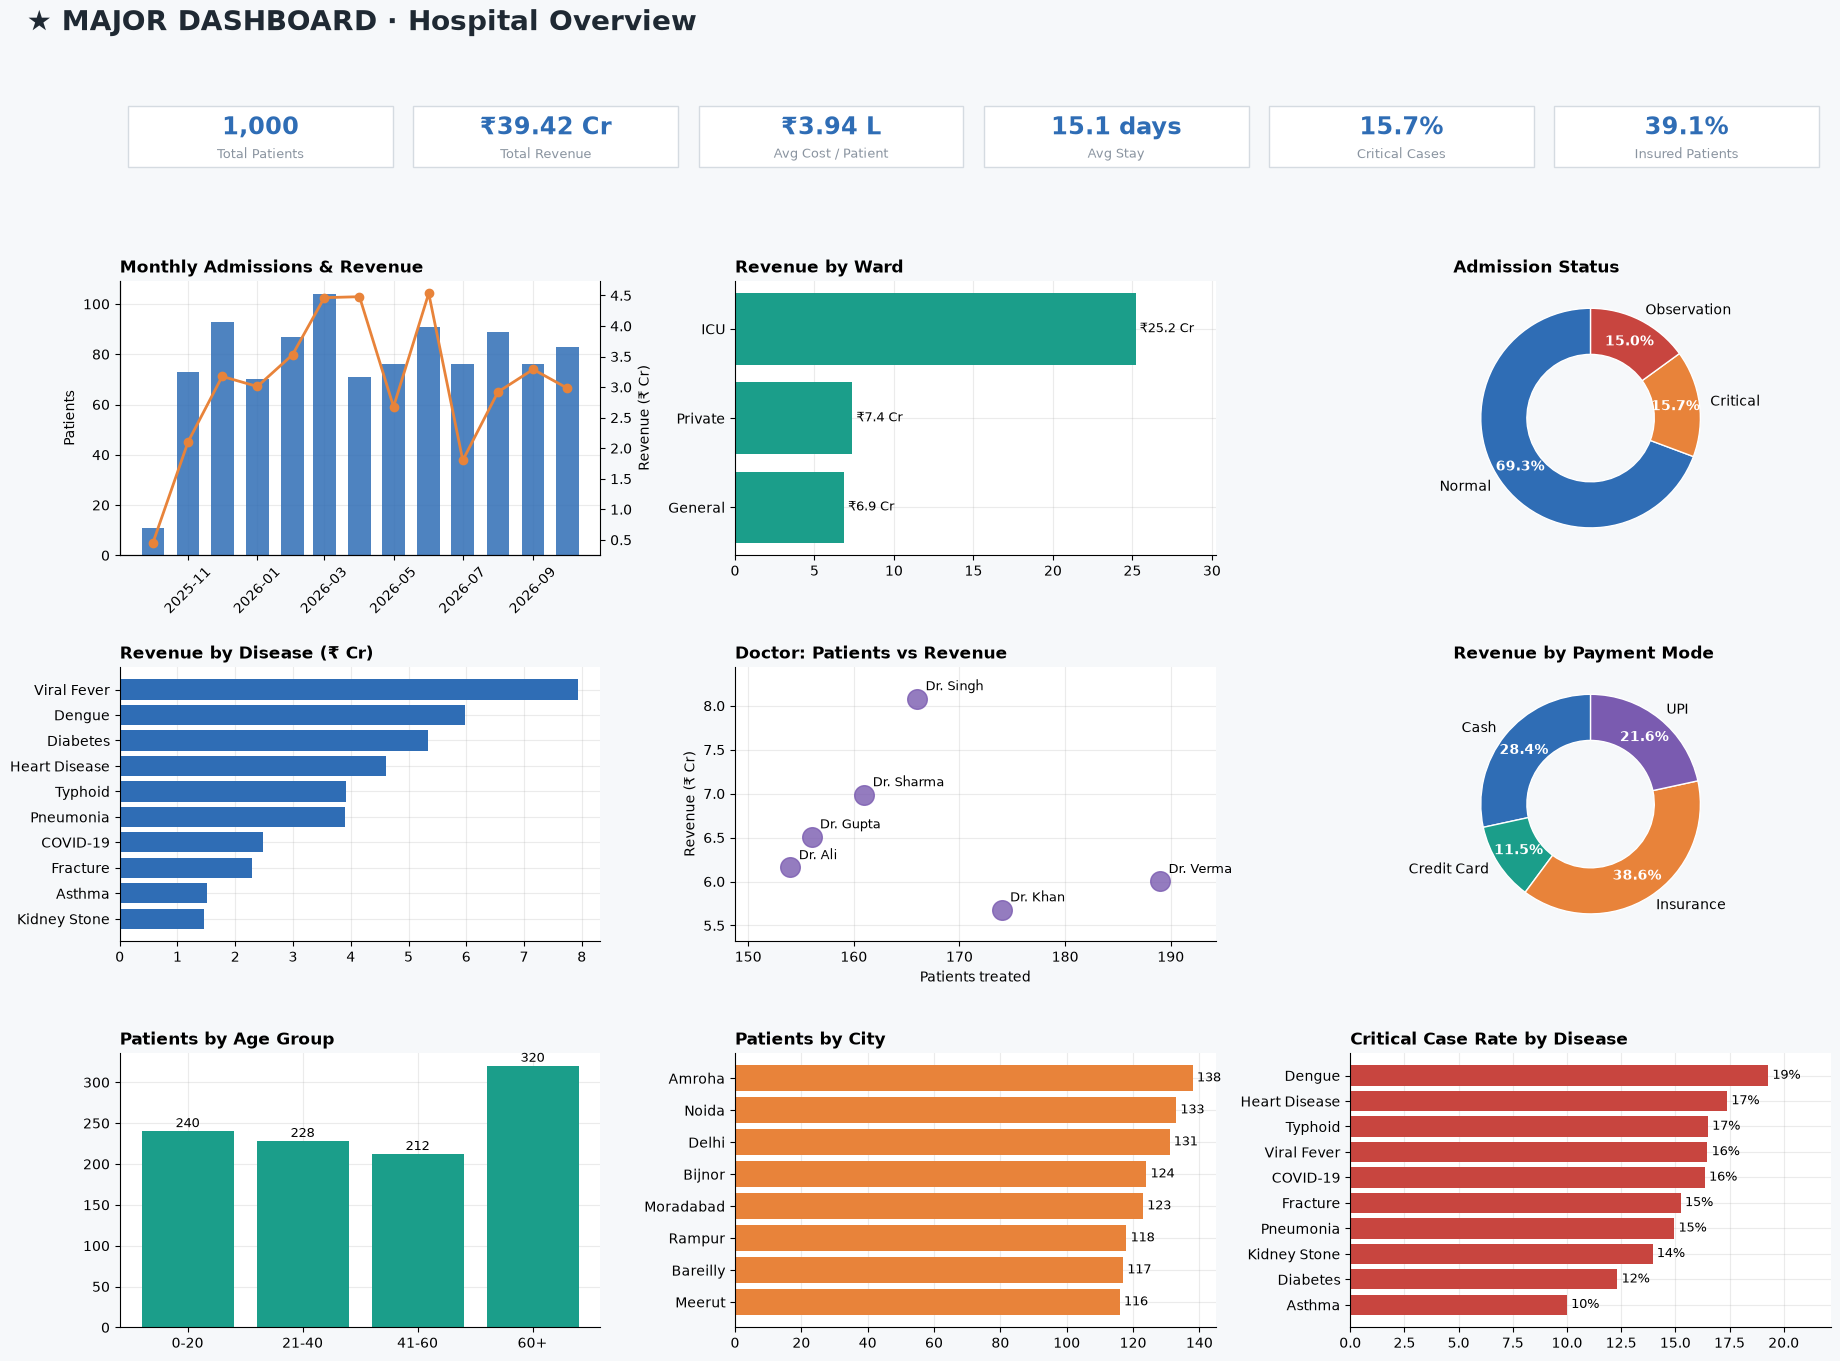

In [9]:
age_order = ["0-20", "21-40", "41-60", "60+"]
kpis = [
    ("Total Patients",      f"{len(master):,}"),
    ("Total Revenue",       inr(master["Treatment Cost (INR)"].sum())),
    ("Avg Cost / Patient",  inr(master["Treatment Cost (INR)"].mean())),
    ("Avg Stay",            f"{master['Length of Stay (Days)'].mean():.1f} days"),
    ("Critical Cases",      f"{(master['Admission Status']=='Critical').mean():.1%}"),
    ("Insured Patients",    f"{(master['Payment Mode']=='Insurance').mean():.1%}"),
]
fig, ax = new_dashboard("★ MAJOR DASHBOARD · Hospital Overview", kpis, 3, 3)

m = master.groupby("Month").agg(patients=("Patient ID", "count"), revenue=("Treatment Cost (INR)", "sum"))
ax[0][0].bar(m.index, m["patients"], width=20, color=C["blue"], alpha=.85)
ax[0][0].set_ylabel("Patients"); ax[0][0].set_title("Monthly Admissions & Revenue")
ax[0][0].tick_params(axis="x", rotation=45)
t = ax[0][0].twinx(); t.plot(m.index, m["revenue"]/1e7, color=C["orange"], marker="o", lw=2)
t.set_ylabel("Revenue (₹ Cr)"); t.grid(False); t.spines["right"].set_visible(True)

w = master.groupby("Ward Type")["Treatment Cost (INR)"].sum().sort_values()
ax[0][1].barh(w.index, w/1e7, color=C["teal"]); bar_labels(ax[0][1], "₹{:.1f} Cr", horizontal=True)
ax[0][1].set_title("Revenue by Ward"); ax[0][1].margins(x=.2)

s = master["Admission Status"].value_counts()
donut(ax[0][2], s.index, s.values, [C["blue"], C["orange"], C["red"]]); ax[0][2].set_title("Admission Status")

d = master.groupby("Disease").agg(n=("Patient ID", "count"), rev=("Treatment Cost (INR)", "sum")).sort_values("rev")
ax[1][0].barh(d.index, d["rev"]/1e7, color=C["blue"]); ax[1][0].set_title("Revenue by Disease (₹ Cr)")

dr = master.groupby("Doctor").agg(patients=("Patient ID", "count"), revenue=("Treatment Cost (INR)", "sum"))
sc = ax[1][1].scatter(dr["patients"], dr["revenue"]/1e7, s=200, color=C["purple"], alpha=.8)
for n, r in dr.iterrows(): ax[1][1].annotate(n, (r["patients"], r["revenue"]/1e7), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax[1][1].set_xlabel("Patients treated"); ax[1][1].set_ylabel("Revenue (₹ Cr)"); ax[1][1].set_title("Doctor: Patients vs Revenue")
ax[1][1].margins(.15)

p = master.groupby("Payment Mode")["Treatment Cost (INR)"].sum()
donut(ax[1][2], p.index, p.values, PALETTE); ax[1][2].set_title("Revenue by Payment Mode")

a = master["Age Group"].value_counts().reindex(age_order)
ax[2][0].bar(a.index, a.values, color=C["teal"]); bar_labels(ax[2][0]); ax[2][0].set_title("Patients by Age Group")

c = master["City"].value_counts().sort_values()
ax[2][1].barh(c.index, c.values, color=C["orange"]); bar_labels(ax[2][1], horizontal=True); ax[2][1].set_title("Patients by City")

cr = (master.assign(c=(master["Admission Status"]=="Critical")).groupby("Disease")["c"].mean()*100).sort_values()
ax[2][2].barh(cr.index, cr.values, color=C["red"]); bar_labels(ax[2][2], "{:.0f}%", horizontal=True)
ax[2][2].set_title("Critical Case Rate by Disease"); ax[2][2].margins(x=.15)
plt.show()